# 01_2 PCA of the tile embeddings: how much dimensionality does UNI2-h need?

**Overview.** This notebook studies the principal component analysis (PCA) of the 1536-dimensional UNI2-h tile embeddings saved by `01_1_wsi_to_vectors.ipynb`. It asks how reducing the dimension affects (1) the explained variance, (2) the eigenvalue spectrum and its effective rank, (3) the reconstruction of held-out embeddings and (4) the preservation of the cosine neighbourhood structure of the tiles. The results guide the choice of a dimension for later work; no synthetic data are generated and no classifier is trained here.

One PCA is fitted on a slide-balanced sample of tiles from the official **Training** slides only and is reused for every candidate dimension (the first *d* components). It is evaluated on **Validation** slides of patients that do not appear in Training. The official Testing slides are never used for fitting or evaluation; they are only transformed in the last section, when the reduced embeddings are stored.

The reduced vectors are written to `PCA_OUTPUT_DIR/pca_<d>/UNI2-h/<slide>.pt` (same keys as the original files), with the fitted PCA (`pca_model.pt`) and the configuration (`metadata.json`). The original files are only read. No figure or report is exported.

```mermaid
flowchart TD
    FEAT[("level_1/UNI2-h/<br/>one .pt file per slide (from 01_1)")] --> SAMP["3. split_fit_eval + sample_tiles"]
    SAMP --> FIT["4. fit_pca<br/>Training sample only"]
    FIT --> VAR["5. variance_table"]
    FIT --> SPEC["6. spectrum_stats"]
    FIT --> REC["7. reconstruction_metrics<br/>Validation sample"]
    FIT --> NB["8. neighbour_preservation<br/>cosine, exact top-k"]
    VAR --> CMP["9. final_comparison + recommend_dimensions"]
    REC --> CMP
    NB --> CMP
    FIT --> SAVE["10. save_pca_embeddings"]
    SAVE --> OUT[("pca_d/UNI2-h/<br/>pca_model.pt, metadata.json")]
```

## 1. Setup

The environment is recorded so the run can be reproduced.

In [1]:
# STEP 1: Standard-library imports and general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('SciPy version:', scipy.__version__)
print('scikit-learn version:', sklearn.__version__)
print('Matplotlib version:', matplotlib.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
PyTorch version: 2.15.0+cu132
Numpy version: 2.5.4
Pandas version: 3.1.1
SciPy version: 1.18.1
scikit-learn version: 1.9.1
Matplotlib version: 3.11.2


The project's own building blocks are imported.

In [2]:
# STEP 1: Standard-library imports
from pathlib import Path

# STEP 2: Import this project's own building blocks
from utils.dataset_overview import build_slide_table
from utils.device import get_device
from utils.mil_train import set_seed
from utils.pca_analysis import (final_comparison, fit_pca, neighbour_preservation, plot_neighbours, plot_reconstruction,
                                plot_spectrum, plot_variance, recommend_dimensions, reconstruction_metrics, sample_tiles,
                                sampling_stats, save_pca_embeddings, spectrum_stats, split_fit_eval, timed, variance_table)

## 2. Constants

Every setting is defined here. `PCA_DIMENSIONS` are the candidate dimensions; the PCA is fitted once with `max(PCA_DIMENSIONS)` components. The sample for fitting is set by `MAX_TILES_PER_SLIDE` and `MAX_FIT_TILES` (`MAX_EVAL_TILES` for the held-out sample); with `STRATIFY_BY_LABEL` the budget is first shared equally among the classes. The neighbourhood analysis uses `N_QUERIES` query tiles and the reference population of the held-out sample, in the space given by `NEIGHBOUR_SPACE`. The PCA is not whitened (`WHITEN`). `SAVE_PCA_EMBEDDINGS` turns the storage of section 10 on; existing outputs are not replaced unless `OVERWRITE` is set.

In [3]:
# Major variables
FEATURES_DIR = Path('/mnt/Scratch/phd_streamembed_features/level_1')    # STEP 1: Folder with one subfolder of .pt files per model (from 01_1)
MODEL_NAME = 'UNI2-h'                                                   # STEP 2: Subfolder with the per-slide features
LABELS_FILE = Path('labels/BRACS.xlsx')                                 # STEP 3: Slide labels, patients and official split
PCA_DIMENSIONS = [32, 64, 128, 256, 384, 512, 768, 1024, 1536]          # STEP 4: Candidate dimensions
SEED = 42                                                               # STEP 5: Seed of every random choice
MAX_TILES_PER_SLIDE, MAX_FIT_TILES, MAX_EVAL_TILES = 500, 200_000, 100_000   # STEP 6: Tiles per slide; total tiles to fit the PCA; total held-out tiles
STRATIFY_BY_LABEL = False                                               # STEP 7: Share the sampling budget equally among the classes
SOLVER, BATCH_SIZE = 'randomized', 20_000                               # STEP 8: 'randomized' or 'incremental'; batch size of the incremental solver
WHITEN = False                                                          # STEP 9: Divide stored scores by the square root of their variance (analysis is never whitened)
N_QUERIES, N_PAIRS, NEIGHBOUR_SPACE = 5000, 200_000, 'scores'           # STEP 10: Query tiles; random pairs for Spearman; 'scores' or 'reconstructed'
SAVE_PCA_EMBEDDINGS = True                                              # STEP 11: Store the reduced embeddings (section 10)
PCA_OUTPUT_DIR = Path('/mnt/Scratch/phd_streamembed_features')          # STEP 12: Receives pca_<d>/<MODEL_NAME>/<slide>.pt
OVERWRITE = True                                                        # STEP 13: Replace existing PCA outputs (default: refuse)
CACHE_FILE = Path('outputs/01_2_pca/neighbours_cache.pt')               # STEP 14: Cache of the original-space neighbours (None = no cache)
set_seed(SEED)
device = get_device()
print('Device:', device)

Device: cuda


## 3. Data and sampling

The slide table gives the class, patient and official set of each slide. The Training slides are the source of the fitting sample and the Validation slides, minus patients that also have Training slides (patient 67), the source of the held-out sample. Each slide contributes at most `MAX_TILES_PER_SLIDE` tiles and the quotas are reduced equally when the total exceeds the budget, so large slides do not dominate. Only the sampled rows are read from the memory-mapped files.

In [4]:
# STEP 1: Slide table and the patient-disjoint split
table = build_slide_table(LABELS_FILE)
labels = dict(zip(table['slide'], table['label'].astype(str)))
split = split_fit_eval(table)
print({k: len(v) for k, v in split.items()})

# STEP 2: Sample the tiles
with timed('sampling'):
    fit_sample = sample_tiles(FEATURES_DIR, MODEL_NAME, split['fit'], labels, MAX_TILES_PER_SLIDE, MAX_FIT_TILES, SEED, STRATIFY_BY_LABEL)
    eval_sample = sample_tiles(FEATURES_DIR, MODEL_NAME, split['eval'], labels, MAX_TILES_PER_SLIDE, MAX_EVAL_TILES, SEED, STRATIFY_BY_LABEL)

# STEP 3: Sampling statistics
fit_stats, eval_stats = sampling_stats(fit_sample, table), sampling_stats(eval_sample, table)
print('Fit sample:', fit_sample['X'].shape, '| missing files:', len(fit_sample['missing']))
print('Held-out sample:', eval_sample['X'].shape, '| missing files:', len(eval_sample['missing']))
display(fit_stats['per_class'])
display(eval_stats['per_class'])
display(fit_stats['per_slide']['sampled'].describe().to_frame('tiles per fit slide').T)

{'fit': 395, 'eval': 63, 'excluded': 2}
[sampling] 1.2 s
Fit sample: (196101, 1536) | missing files: 0
Held-out sample: (30950, 1536) | missing files: 0


,label,slides,patients,available,sampled,share
0,N,27,18,139115,12264,0.062539
1,PB,120,66,1471945,59837,0.305134
2,UDH,56,34,560306,28000,0.142784
3,FEA,24,14,348670,12000,0.061193
4,ADH,28,16,291515,14000,0.071392
5,DCIS,40,21,468547,20000,0.101988
6,IC,100,53,1111056,50000,0.254971


,label,slides,patients,available,sampled,share
0,N,8,4,61580,3941,0.127334
1,PB,11,7,81298,5500,0.177706
2,UDH,9,6,57208,4009,0.129532
3,FEA,6,6,41051,3000,0.096931
4,ADH,8,6,66748,4000,0.129241
5,DCIS,9,6,108525,4500,0.145396
6,IC,12,5,135967,6000,0.193861


,count,mean,std,min,25%,50%,75%,max
tiles per fit slide,395.0,496.458228,33.98141,26.0,500.0,500.0,500.0,500.0


## 4. PCA fit

One PCA is fitted on the Training sample with enough components for every candidate dimension. The solver is randomised (or incremental, set in the constants); the embeddings are centred with the training mean and not whitened, so the components are orthonormal axes and the scores of dimension *d* are the first *d* scores. Candidate dimensions above the number of fitted components are dropped with a message.

In [5]:
# STEP 1: Fit once, reuse for every dimension
with timed('PCA fit'):
    pca, dims = fit_pca(fit_sample['X'], PCA_DIMENSIONS, SOLVER, BATCH_SIZE, SEED)
print('Fitted components:', pca.n_components_, '| usable dimensions:', dims)

# STEP 2: Basic checks
C = pca.components_
assert np.allclose(C[:64] @ C[:64].T, np.eye(min(64, len(C))), atol=1e-3), 'components are not orthonormal'

[PCA fit] 29.8 s
Fitted components: 1536 | usable dimensions: [32, 64, 128, 256, 384, 512, 768, 1024, 1536]


## 5. Explained variance

The explained variance ratio of component *i* is its eigenvalue divided by the total variance of the training sample. The table gives the cumulative variance at each candidate dimension and the number of components needed to reach 90, 95, 99 and 99.5 % (NaN when the fitted components do not reach the level). Explained variance measures retained energy only; it is not used alone to choose a dimension.

,dimensions,explained_variance,residual
0,32,0.488179,5.118207e-01
1,64,0.582082,4.179178e-01
2,128,0.694236,3.057639e-01
3,256,0.806087,1.939129e-01
4,384,0.865025,1.349752e-01
5,512,0.902865,9.713483e-02
6,768,0.949452,5.054802e-02
7,1024,0.976696,2.330375e-02
8,1536,1.000000,-1.192093e-07


,threshold,components
0,0.900,501
1,0.950,773
2,0.990,1218
3,0.995,1320


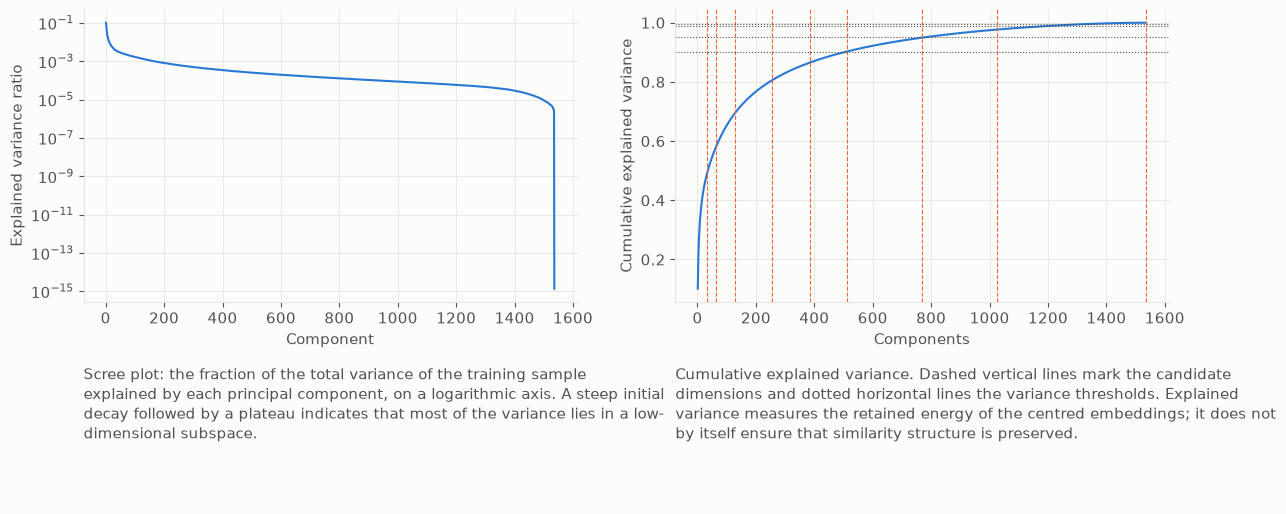

In [6]:
# STEP 1: Tables
var_by_dim, var_by_threshold = variance_table(pca, dims)
display(var_by_dim)
display(var_by_threshold)

# STEP 2: Scree and cumulative plots
_ = plot_variance(pca, dims)

## 6. Eigenvalue spectrum and effective rank

The effective rank is the exponential of the Shannon entropy of the normalised eigenvalues (Roy and Vetterli, 2007). When fewer than 1536 components are fitted, the value is computed on the kept spectrum, is labelled truncated, and is bracketed by two bounds that use the variance left in the unfitted tail. Elbows are candidate dimensions from the shape of the log spectrum, not a selection rule.

Effective rank: 233.8
Bounds for the full spectrum: 233.8 - 233.8
Elbows: {'chord': 1501, 'curvature': 3}


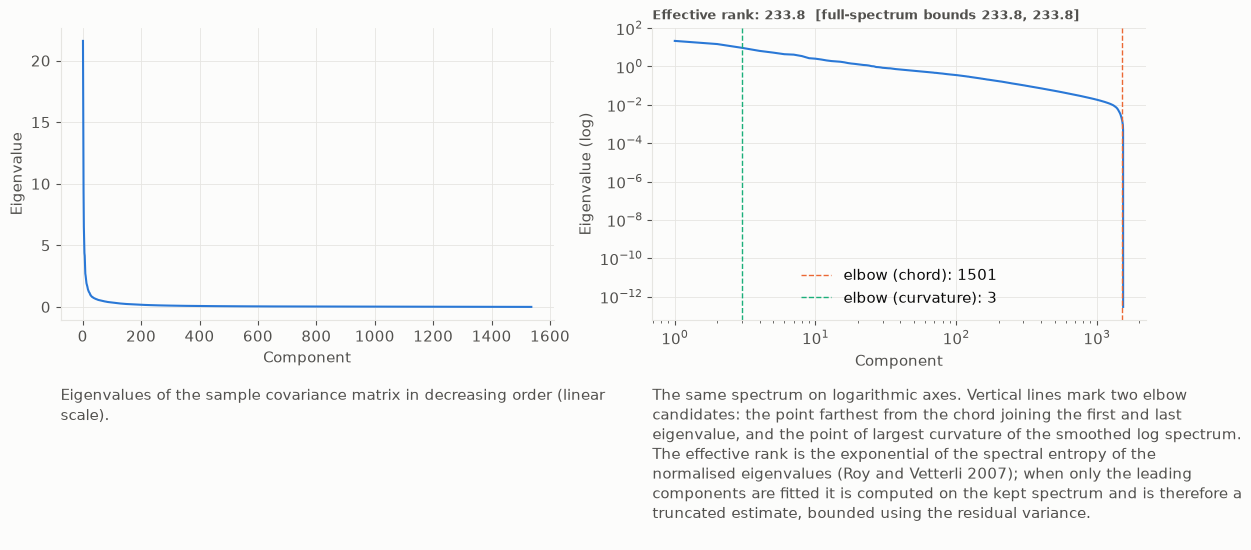

In [7]:
# STEP 1: Spectrum statistics
spec = spectrum_stats(pca)
print(f"Effective rank{' (truncated)' if spec['truncated'] else ''}: {spec['effective_rank']:.1f}")
print('Bounds for the full spectrum: %.1f - %.1f' % spec['effective_rank_bounds'])
print('Elbows:', spec['elbows'])

# STEP 2: Plot
_ = plot_spectrum(spec)

## 7. Reconstruction error

Held-out embeddings are projected, reconstructed in the original 1536-dimensional space from the first *d* scores and compared with the originals. MSE is the mean squared error per coordinate; NMSE divides the total squared error by the total squared deviation of the held-out embeddings from the training mean (NMSE = 1 means no better than the mean vector); cosine is computed between each embedding and its reconstruction. The per-tile error is the mean squared error over the coordinates of one tile.

[reconstruction] 1.3 s


,dimensions,mse,nmse,cosine,error_mean,error_median,error_std,error_p95,error_p99
0,32,7.496326e-02,5.216213e-01,0.774069,7.496326e-02,7.106367e-02,2.212298e-02,1.157902e-01,1.447047e-01
1,64,6.209237e-02,4.320610e-01,0.817050,6.209237e-02,5.827546e-02,1.980902e-02,9.839727e-02,1.271931e-01
2,128,4.652089e-02,3.237091e-01,0.865882,4.652089e-02,4.276744e-02,1.731627e-02,7.871424e-02,1.056776e-01
3,256,3.040904e-02,2.115970e-01,0.914328,3.040904e-02,2.732382e-02,1.317977e-02,5.535904e-02,7.818767e-02
4,384,2.162689e-02,1.504877e-01,0.939814,2.162689e-02,1.914443e-02,1.016138e-02,4.075828e-02,6.019857e-02
5,512,1.582149e-02,1.100916e-01,0.956317,1.582149e-02,1.385345e-02,7.917065e-03,3.056064e-02,4.694221e-02
6,768,8.456160e-03,5.884100e-02,0.976881,8.456160e-03,7.281498e-03,4.597892e-03,1.678487e-02,2.702873e-02
7,1024,3.969932e-03,2.762422e-02,0.989203,3.969932e-03,3.377473e-03,2.252012e-03,7.924116e-03,1.321567e-02
8,1536,3.068971e-13,2.135500e-12,1.000000,3.068971e-13,2.887556e-13,9.244031e-14,4.811264e-13,5.912158e-13


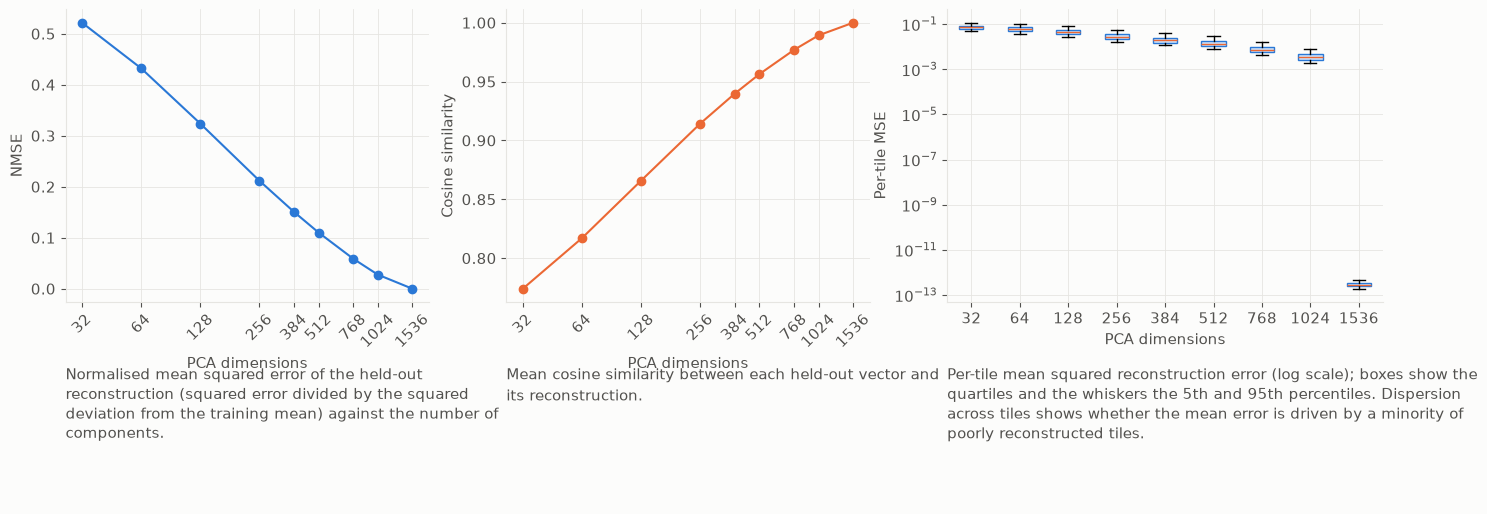

In [8]:
# STEP 1: Metrics for every dimension from one projection
with timed('reconstruction'):
    recon, recon_tiles = reconstruction_metrics(pca, eval_sample['X'], dims)
display(recon)

# STEP 2: Plots
_ = plot_reconstruction(recon, recon_tiles)

## 8. Neighbourhood preservation

For `N_QUERIES` random held-out tiles, the nearest neighbours in the original space (cosine, exact search over the whole held-out reference sample, the query itself excluded) are compared with those in each reduced space. The same queries and reference population are used for every dimension and the original-space neighbours are cached. Recall@k is the mean fraction of the k original neighbours recovered; the overlap is the number of shared neighbours among the top 10; Spearman is the rank correlation of cosine similarity over random tile pairs. Tiles of the same slide are often mutual neighbours, so the per-slide and per-class breakdowns are shown. FAISS is not installed; an exact chunked search in torch is used instead.

[neighbour preservation] 1.5 s


,dimensions,recall@10,recall@20,overlap_mean,overlap_median,spearman
0,32,0.45134,0.48908,4.5134,5.0,0.601609
1,64,0.55802,0.59125,5.5802,6.0,0.611570
2,128,0.65796,0.68070,6.5796,7.0,0.616626
3,256,0.73762,0.75259,7.3762,8.0,0.620764
4,384,0.76926,0.77982,7.6926,8.0,0.622227
5,512,0.78492,0.79379,7.8492,8.0,0.623019
6,768,0.79936,0.80702,7.9936,8.0,0.623981
7,1024,0.80584,0.81227,8.0584,8.0,0.624380
8,1536,0.80992,0.81527,8.0992,8.0,0.624691


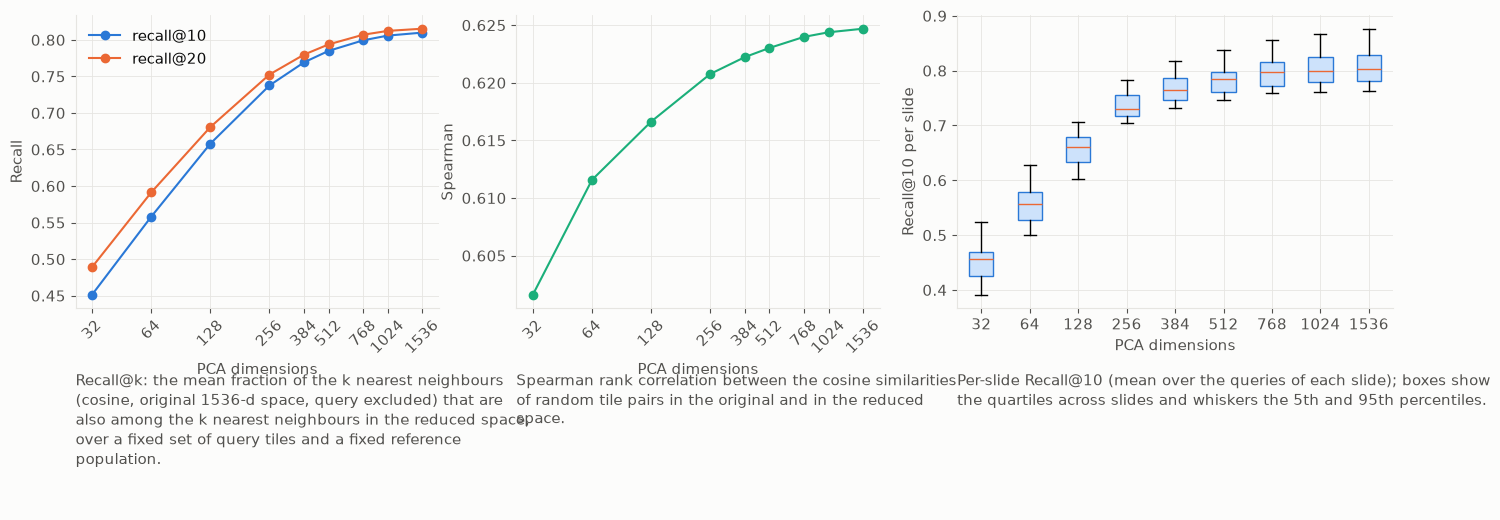

dimensions,32,64,128,256,384,512,768,1024,1536
label,,,,,,,,,
ADH,0.421417,0.526570,0.628986,0.714171,0.754428,0.772142,0.789050,0.798390,0.801771
DCIS,0.448138,0.565517,0.653241,0.727724,0.760276,0.775034,0.789241,0.796690,0.799586
FEA,0.444937,0.548101,0.650211,0.730169,0.755063,0.763713,0.777637,0.784177,0.786498
IC,0.433758,0.531316,0.640658,0.730892,0.767728,0.788641,0.806369,0.813907,0.819002
N,0.438013,0.549369,0.660568,0.742587,0.772555,0.789117,0.802839,0.806467,0.809779
PB,0.485426,0.593191,0.682340,0.755000,0.782553,0.793404,0.804894,0.811383,0.815745
UDH,0.476807,0.582681,0.683283,0.755873,0.783283,0.801506,0.814458,0.818373,0.824548


In [9]:
# STEP 1: Reference labels and the neighbourhood analysis
ref_label = np.array([labels[eval_sample['names'][i]] for i in eval_sample['slide']])
with timed('neighbour preservation'):
    neigh = neighbour_preservation(eval_sample['X'], pca, dims, eval_sample['slide'], ref_label, N_QUERIES, (10, 20),
                                   N_PAIRS, SEED, NEIGHBOUR_SPACE, cache_path=CACHE_FILE, device=device)
display(neigh['summary'])

# STEP 2: Plots and breakdowns
_ = plot_neighbours(neigh)
display(neigh['per_label'].pivot(index='label', columns='dimensions', values='recall@10'))

## 9. Final comparison

One table joins the metrics of all candidate dimensions. The recommended dimensions are the smallest ones that reach a given Recall@10 (the neighbourhood structure is what the later work depends on), so the choice does not rest on explained variance alone. Read the interpretation below against the numbers of your own run.

In [10]:
# STEP 1: Comparison table and candidate dimensions
comparison = final_comparison(var_by_dim, recon, neigh['summary'])
display(comparison)
recommended = recommend_dimensions(comparison, recall_targets=(0.80, 0.90, 0.95))
display(recommended)

,Dimensions,Explained variance,NMSE,Cosine similarity,Recall@10,Recall@20,Spearman
0,32,0.488179,5.216213e-01,0.774069,0.45134,0.48908,0.601609
1,64,0.582082,4.320610e-01,0.817050,0.55802,0.59125,0.611570
2,128,0.694236,3.237091e-01,0.865882,0.65796,0.68070,0.616626
3,256,0.806087,2.115970e-01,0.914328,0.73762,0.75259,0.620764
4,384,0.865025,1.504877e-01,0.939814,0.76926,0.77982,0.622227
5,512,0.902865,1.100916e-01,0.956317,0.78492,0.79379,0.623019
6,768,0.949452,5.884100e-02,0.976881,0.79936,0.80702,0.623981
7,1024,0.976696,2.762422e-02,0.989203,0.80584,0.81227,0.624380
8,1536,1.000000,2.135500e-12,1.000000,0.80992,0.81527,0.624691


,Recall@10 target,Dimensions,Explained variance,NMSE,Cosine similarity,Recall@10,Recall@20,Spearman
0,0.80,1024.0,0.976696,0.027624,0.989203,0.80584,0.81227,0.62438
1,0.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.95,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interpretation.** *(to be written after the run on the workstation: state the dimensions of `recommended`, the dimension where Recall@10 and NMSE flatten, and the effective rank, and name 2 to 3 promising dimensions for the synthetic embedding generation.)*

## 10. Storage of the reduced embeddings

The fitted PCA is applied, one slide at a time, to every labelled slide (Training, Validation and Testing; the PCA is never refitted) and the first *d* scores are written to `pca_<d>/UNI2-h/<slide>.pt`, keeping the tile order, coordinates and `tile_params` of the original file and adding `slide`, `label`, `patient`, `set`. `pca_model.pt` holds the mean, components and explained variance and `metadata.json` the configuration and the fit/held-out slide lists. Existing outputs are never replaced unless `OVERWRITE` is set, and nothing is written into the folder of the original embeddings.

In [11]:
# STEP 1: Configuration saved with the models
config = {'seed': SEED, 'solver': SOLVER, 'dimensions': dims, 'max_tiles_per_slide': MAX_TILES_PER_SLIDE,
          'max_fit_tiles': MAX_FIT_TILES, 'stratify_by_label': STRATIFY_BY_LABEL, 'fit_slides': fit_sample['names'],
          'eval_slides': eval_sample['names'], 'excluded_slides': split['excluded'], 'fit_tiles': int(len(fit_sample['X'])),
          'explained_variance_at_dims': dict(zip(dims, var_by_dim['explained_variance'])), 'features_dir': FEATURES_DIR}

# STEP 2: Save
if SAVE_PCA_EMBEDDINGS:
    with timed('storage'):
        saved = save_pca_embeddings(FEATURES_DIR, PCA_OUTPUT_DIR, MODEL_NAME, pca, dims, table, config, WHITEN, OVERWRITE)
    print(len(saved['saved']), 'slides saved;', len(saved['missing']), 'without a feature file')

[storage] 101.5 s
547 slides saved; 0 without a feature file


## 11. Validation checks

The saved files are reloaded for one slide and compared with a fresh projection of the original embeddings: shape, tile order, coordinates and values must agree, and the original file must be unchanged.

In [12]:
# STEP 1: Fit and held-out sets share no patient and exclude Testing
patients = table.set_index('slide')['patient']
sets = table.set_index('slide')['set']
assert not set(patients[fit_sample['names']]) & set(patients[eval_sample['names']])
assert not (sets[fit_sample['names'] + eval_sample['names']] == 'Testing').any()

# STEP 2: Reload one saved slide for the smallest and the largest dimension
if SAVE_PCA_EMBEDDINGS:
    slide = saved['saved'][0]
    original = torch.load(FEATURES_DIR / MODEL_NAME / f'{slide}.pt', weights_only=True, mmap=True)
    scores = (original['cls_features'].float().numpy() - pca.mean_) @ pca.components_.T
    if WHITEN:
        scores = scores / np.sqrt(pca.explained_variance_)
    for d in (dims[0], dims[-1]):
        reduced = torch.load(PCA_OUTPUT_DIR / f'pca_{d}' / MODEL_NAME / f'{slide}.pt', weights_only=True)
        assert reduced['cls_features'].shape == (len(original['cls_features']), d)
        assert torch.equal(reduced['coordinates'], original['coordinates'])
        assert np.allclose(reduced['cls_features'].numpy(), scores[:, :d], atol=1e-3)
    print('Saved files agree with a fresh projection of', slide)

Saved files agree with a fresh projection of BRACS_264
